# Nhận dạng hoạt động con người từ cảm biến điện thoại bằng CNN

## Tóm tắt nghiên cứu

Nghiên cứu phân tích và tái hiện một phần hướng tiếp cận của Ronao & Cho (2016) trên UCI HAR. Ba cấu hình CNN được huấn luyện với ba seed, chia dữ liệu theo người và lựa chọn mô hình bằng validation trước khi đánh giá test. Phần mở rộng khảo sát năm biểu diễn cảm biến và trả lời các câu hỏi thực tế về người mới, nhầm ngồi–đứng và giá trị của các nhóm tín hiệu.

**Đây là notebook duy nhất của dự án:** từ trên xuống dưới là vấn đề, phương pháp, mã huấn luyện, kết quả và thảo luận của nghiên cứu đã thực hiện. Mọi mô hình và vòng `model.fit()` được định nghĩa trực tiếp, không chạy notebook hoặc script huấn luyện khác.

**Bằng chứng đã có:** 9 lượt CNN-A/B/C và test đã khóa; 15 lượt khảo sát cảm biến trên validation. Hai phần có phạm vi kết luận khác nhau và được phân biệt xuyên suốt notebook.

### Mục lục

1. Vấn đề và câu hỏi nghiên cứu
2. Môi trường và dữ liệu
3. Thiết kế thực nghiệm, chuẩn hóa và baseline
4. Kiến trúc và huấn luyện CNN-A/B/C
5. Kết quả validation và đánh giá test gốc
6. Người mới và lỗi ngồi–đứng
7. Vai trò của các nhóm cảm biến
8. Tổng hợp câu trả lời, thảo luận và kết luận
9. Tài liệu tham khảo

### Cách sử dụng

Chọn kernel `.venv/Scripts/python.exe`, giữ `RUN_MODE="inspect"`, rồi **Restart Kernel → Run All**. Chế độ này xác minh và đọc hiện vật đã có, tính lại bảng và vẽ hình; không huấn luyện hoặc ghi đè kết quả. Các đầu ra đã được lưu trong notebook để đọc ngay.

Muốn tái chạy: chọn `smoke` (một lượt CNN-B và một lượt cảm biến, mỗi lượt một epoch) hoặc `train` (9 lượt kiến trúc + 15 lượt cảm biến). Đặt `RUN_NAME` mới, **Save → Restart Kernel → Run All**. Đầu ra mới nằm trong `notebook_runs/RUN_NAME/architectures/` và `sensors/`; chỉ đánh giá validation. Các bảng test luôn là bằng chứng tham chiếu của đợt gốc, không phải test của các lượt tái chạy.

Một notebook không có nghĩa là toàn bộ dữ liệu/checkpoint được nhúng vào tệp: chạy lại cần thư mục Dataset, results và practical_results đi kèm. Checkpoint/cache không được Git theo dõi; xem các đầu ra đã lưu nếu chưa chuyển đủ hiện vật.

## 1. Vấn đề và câu hỏi nghiên cứu

Điện thoại ghi nhận gia tốc và vận tốc góc theo thời gian. Bài toán là phân loại mỗi cửa sổ tín hiệu thành đi bộ, lên cầu thang, xuống cầu thang, ngồi, đứng hoặc nằm. CNN 1D học các mẫu cục bộ và tổ hợp đặc trưng từ chuỗi cảm biến; hiệu quả cần được kiểm tra trên người không xuất hiện trong huấn luyện.

| Câu hỏi | Thiết kế trả lời | Phạm vi bằng chứng |
|---|---|---|
| CNN nhận dạng người mới tốt đến đâu? | CNN-B, test tách theo người, ba seed | Test gốc đã khóa |
| Ba cấu hình độ sâu khác nhau cho kết quả thế nào? | CNN-A/B/C cùng split và ba seed | Chọn theo validation trước test |
| Mô hình hay nhầm hoạt động nào? | Confusion matrix, Recall và phân tích lỗi | Dự đoán test đã lưu |
| Vì sao ngồi–đứng là trường hợp khó? | Đếm lỗi, mô tả tín hiệu và đặt giả thuyết | Phân tích mô tả, không xác lập nguyên nhân |
| Chỉ gia tốc kế có đủ không, thêm con quay có ích không? | Năm nhóm kênh × ba seed, CNN-B | Mở rộng khám phá trên validation |

### Công trình gốc và phạm vi tái hiện

Ronao & Cho dùng UCI HAR, sáu kênh theo mô tả của bài báo, khảo sát nhiều cấu hình; CNN không FFT tốt nhất có ba tầng tích chập 96–192–192 feature maps và Dense 1000, Accuracy 94,79%. Thiết lập FFT riêng đạt 95,75%. Nhóm sử dụng chín kênh, kiến trúc nhỏ hơn, Adam và validation theo người được công khai, nên đây là **tái hiện một phần**, chưa phải tái lập chính xác hoặc phép so sánh tương đương.

Ba seed phản ánh biến động do huấn luyện trên cùng split; không thay thế nhiều split hoặc nhiều bộ dữ liệu. Không đặt mục tiêu phải vượt điểm bài báo gốc.

## 2. Môi trường và dữ liệu

UCI HAR gồm 30 người, sáu hoạt động, tần số 50 Hz. Mỗi cửa sổ có 128 thời điểm (2,56 giây), chồng lấn 50%. Tín hiệu trong dataset đã qua tiền xử lý. CNN sử dụng các tệp `Inertial Signals`, không sử dụng 561 đặc trưng tính sẵn trong `X_train.txt`/`X_test.txt`.

Thứ tự chín kênh: gia tốc cơ thể X/Y/Z → con quay X/Y/Z → gia tốc tổng X/Y/Z. Hai loại gia tốc là hai biểu diễn liên quan đến cùng cảm biến, không phải hai cảm biến vật lý riêng.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, importlib.metadata
from datetime import datetime, timezone

ROOT = Path.cwd().resolve()
if not (ROOT / "Dataset").is_dir() and (ROOT.parent / "Dataset").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "Dataset" / "UCI HAR Dataset"
SOURCE_RESULTS = ROOT / "results"
REFERENCE_SENSOR_RESULTS = ROOT / "practical_results" / "sensor_study_v1"
OUTPUT_BASE = ROOT / "notebook_runs"
RUN_MODE = "inspect"  # inspect | smoke | train
RUN_NAME = "har_research_v1"  # đổi tên trước mỗi lần huấn luyện mới
MODELS = ["cnn_a", "cnn_b", "cnn_c"]
SEEDS = [42, 123, 2026]
VALIDATION_SUBJECTS = [5, 11, 19, 26]
LEARNING_RATE, BATCH_SIZE, MAX_EPOCHS, PATIENCE, DROPOUT = .001, 64, 50, 8, .3
NEW_RUN_ROOT = OUTPUT_BASE / RUN_NAME / "architectures"
STUDY_ROOT = REFERENCE_SENSOR_RESULTS if RUN_MODE == "inspect" else OUTPUT_BASE / RUN_NAME / "sensors"
STUDY_OUTPUT_BASE = REFERENCE_SENSOR_RESULTS.parent if RUN_MODE == "inspect" else OUTPUT_BASE
MODE = "inspect"  # bộ dữ liệu gốc luôn được đọc và xác minh, không chuẩn bị lại
if RUN_MODE not in {"inspect", "smoke", "train"}:
    raise ValueError("RUN_MODE phải là inspect, smoke hoặc train")
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache" / "matplotlib")
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Project:", ROOT, "Mode:", RUN_MODE)
print("Python:", sys.executable)
print("New architecture runs:", NEW_RUN_ROOT)
print("Sensor study:", STUDY_ROOT)

Project: E:\PPNCKH\SGU26_PPNCKH_Group Mode: inspect
Python: E:\PPNCKH\SGU26_PPNCKH_Group\.venv\Scripts\python.exe
New architecture runs: E:\PPNCKH\SGU26_PPNCKH_Group\notebook_runs\har_research_v1\architectures
Sensor study: E:\PPNCKH\SGU26_PPNCKH_Group\practical_results\sensor_study_v1


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("TensorFlow đã khởi tạo; giữ cấu hình thread hiện có. Restart kernel nếu cần đổi.")
tf.config.experimental.enable_op_determinism()
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
pd.set_option("display.max_columns", 30)

Python: 3.12.13
TensorFlow: 2.21.0


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
GROUPS = {
    "total_acc": [6, 7, 8],
    "gyro": [3, 4, 5],
    "total_acc_gyro": [6, 7, 8, 3, 4, 5],
    "body_acc_gyro": [0, 1, 2, 3, 4, 5],
    "all_9": list(range(9)),
}

def prepare_channels(fit_raw, validation_raw, group):
    if group not in GROUPS:
        raise ValueError("Nhóm kênh không hợp lệ")
    a, b = fit_raw[:, :, GROUPS[group]], validation_raw[:, :, GROUPS[group]]
    if a.ndim != 3 or len(a) == 0 or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Dữ liệu không hữu hạn hoặc rỗng")
    mean = a.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
    std = np.maximum(a.std(axis=(0, 1), keepdims=True, dtype=np.float64), 1e-8)
    return ((a-mean)/std).astype(np.float32), ((b-mean)/std).astype(np.float32), mean, std

def calculate_metrics(truth, predictions):
    cm = confusion_matrix(truth, predictions, labels=list(range(6)))
    report = classification_report(truth, predictions, labels=list(range(6)), target_names=ACTIVITIES,
                                   output_dict=True, zero_division=0)
    return {
        "accuracy": float(accuracy_score(truth, predictions)),
        "macro_f1": float(f1_score(truth, predictions, labels=list(range(6)), average="macro", zero_division=0)),
        "sit_stand_errors": int(cm[3, 4] + cm[4, 3]),
        "sitting_to_standing": int(cm[3, 4]), "standing_to_sitting": int(cm[4, 3]),
        "total_errors": int(np.sum(cm) - np.trace(cm)),
        "confusion_matrix": cm.tolist(), "report": report,
        **{f"recall_{name}": float(report[name]["recall"]) for name in ACTIVITIES},
    }

def validate_predictions(frame, index_column):
    keys = [index_column, "subject_id", "y_true", "y_pred"]
    values = frame[keys].to_numpy(dtype=float)
    if len(frame) == 0 or not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError("Chỉ số/nhãn/subject phải nguyên và hữu hạn")
    if frame[index_column].duplicated().any() or (frame[index_column] < 0).any():
        raise ValueError("Chỉ số cửa sổ trùng hoặc âm")
    if not np.isin(frame.subject_id, np.arange(1, 31)).all():
        raise ValueError("ID người không hợp lệ")
    if not np.isin(frame[["y_true", "y_pred"]], np.arange(6)).all():
        raise ValueError("Nhãn không hợp lệ")
    p = frame[["p_"+name for name in ACTIVITIES]].to_numpy()
    if not np.isfinite(p).all() or (p < 0).any() or (p > 1).any() or not np.allclose(p.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Xác suất không hợp lệ")
    if not np.array_equal(p.argmax(axis=1), frame.y_pred):
        raise ValueError("Dự đoán không khớp xác suất")
    return frame

In [4]:
def validate_output(run_root, output_base, source_results):
    run_root = Path(run_root).resolve()
    output_base = Path(output_base).resolve()
    source_results = Path(source_results).resolve()
    if run_root == source_results or run_root.is_relative_to(source_results):
        raise ValueError("Không ghi lượt huấn luyện mới vào results gốc")
    if run_root == output_base or not run_root.is_relative_to(output_base):
        raise ValueError("RUN_NAME phải nằm bên trong notebook_runs")
    return run_root


def create_run_folder(folder):
    Path(folder).mkdir(parents=True, exist_ok=False)



def validate_seeds(seeds):
    if not seeds or any(not isinstance(s, int) or isinstance(s, bool) or not 0 <= s < 2**32 for s in seeds):
        raise ValueError("Seed không hợp lệ")
    if len(set(seeds)) != len(seeds):
        raise ValueError("Seed trùng")

def validate_location(target, base, frozen):
    target, base, frozen = Path(target).resolve(), Path(base).resolve(), Path(frozen).resolve()
    if target == frozen or target.is_relative_to(frozen) or target == base or not target.is_relative_to(base):
        raise ValueError("Output phải ở bên trong thư mục đầu ra đã cấu hình và ngoài results gốc")
    return target

def reserve_output(target, base, frozen):
    target = validate_location(target, base, frozen)
    target.mkdir(parents=True, exist_ok=False)
    return target

def reserve_research_run(architecture_root, sensor_root, output_base, source_results):
    architecture_root = validate_output(architecture_root, output_base, source_results)
    sensor_root = validate_location(sensor_root, output_base, source_results)
    parent = architecture_root.parent
    if architecture_root == sensor_root or parent != sensor_root.parent or parent == Path(output_base).resolve():
        raise ValueError("Both experiment sections must share one named run directory")
    parent.mkdir(parents=True, exist_ok=False)
    return parent


In [5]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024*1024), b""):
            digest.update(block)
    return digest.hexdigest()

def save_json(path, payload):
    Path(path).write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False)+"\n", encoding="utf-8")

def save_figure(fig, name):
    if RUN_MODE != "inspect":
        fig.savefig(STUDY_ROOT / "figures" / name, dpi=180)
    plt.show()
    plt.close(fig)

### 2.1. Kiểm tra tính toàn vẹn dữ liệu tham chiếu

Đọc cache và SHA-256 đã lưu; không ghi lại thống kê hoặc split gốc. Việc xác minh chỉ đọc tệp, không đưa test vào huấn luyện hay lựa chọn mô hình.

In [6]:
from har_project.data import file_hash
summary_path = ROOT / "results/data_summary.json"
prepared_path = ROOT / "results/prepared/dataset.npz"
if not summary_path.exists() or not prepared_path.exists():
    raise FileNotFoundError("Cần chuyển đủ cache và kết quả tham chiếu để tái hiện toàn bộ nghiên cứu đã thực hiện.")
summary = json.loads(summary_path.read_text(encoding="utf-8"))
assert file_hash(prepared_path) == summary["prepared_sha256"], "Cache không khớp SHA-256"
for relative, expected in summary["input_sha256"].items():
    assert file_hash(ROOT / "Dataset/UCI HAR Dataset" / relative) == expected, f"Dữ liệu nguồn thay đổi: {relative}"
for split in ("fit_train", "validation", "test"):
    print(split, summary[split]["shape"], summary[split]["subjects"])
print("Subject overlap:", summary["subject_overlap"])

fit_train [5982, 128, 9] [1, 3, 6, 7, 8, 14, 15, 16, 17, 21, 22, 23, 25, 27, 28, 29, 30]
validation [1370, 128, 9] [5, 11, 19, 26]
test [2947, 128, 9] [2, 4, 9, 10, 12, 13, 18, 20, 24]
Subject overlap: []


### 2.2. Đọc tín hiệu huấn luyện

Các bước xử lý và huấn luyện bên dưới chỉ tải official train. Nhãn nguồn 1–6 được chuyển thành 0–5. Phải giữ đúng liên kết giữa chỉ số cửa sổ, nhãn và người.

In [7]:
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
train_dir = DATA_DIR / "train"
raw_labels = np.loadtxt(train_dir / "y_train.txt", ndmin=1)
raw_subjects = np.loadtxt(train_dir / "subject_train.txt", ndmin=1)
if raw_labels.ndim != 1 or raw_subjects.shape != raw_labels.shape:
    raise ValueError("Nhãn và subject không cùng số dòng")
if not np.isin(raw_labels, np.arange(1, 7)).all() or not np.isin(raw_subjects, np.arange(1, 31)).all():
    raise ValueError("Nhãn hoặc subject không hợp lệ")
y = raw_labels.astype(np.int64) - 1
subjects = raw_subjects.astype(np.int64)

signal_files = [train_dir / "Inertial Signals" / f"{channel}_train.txt" for channel in CHANNELS]
signals = []
for path in signal_files:
    signal = np.loadtxt(path, dtype=np.float32, ndmin=2)
    if signal.shape != (len(y), 128) or not np.isfinite(signal).all():
        raise ValueError(f"Kích thước hoặc giá trị không hợp lệ: {path.name}")
    signals.append(signal)
X = np.stack(signals, axis=-1)
print("X:", X.shape, X.dtype)
print("y:", y.shape, "labels:", np.unique(y))
print("Subjects:", np.unique(subjects))

X: (7352, 128, 9) float32
y: (7352,) labels: [0 1 2 3 4 5]
Subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]


## 3. Thiết kế thực nghiệm và tiền xử lý

Official train có 7.352 cửa sổ của 21 người. Giữ người 5, 11, 19, 26 làm validation: 1.370 cửa sổ; fit-train còn 5.982 cửa sổ của 17 người. Test gốc gồm 2.947 cửa sổ của chín người khác. Không chia ngẫu nhiên từng cửa sổ vì các cửa sổ cùng người có liên hệ và có thể chồng lấn.

Mean/std chỉ học từ fit-train, theo từng kênh trên trục mẫu và thời gian. Cùng thống kê được áp dụng nguyên trạng cho validation; test gốc đã được xử lý theo quy tắc này trước khi khóa kết quả.

In [8]:
if not set(VALIDATION_SUBJECTS).issubset(set(subjects.tolist())):
    raise ValueError("Thiếu người validation trong dữ liệu train")
validation_mask = np.isin(subjects, VALIDATION_SUBJECTS)
fit_indices = np.flatnonzero(~validation_mask)
validation_indices = np.flatnonzero(validation_mask)
x_fit_raw, y_fit = X[fit_indices], y[fit_indices]
x_val_raw, y_val = X[validation_indices], y[validation_indices]
if set(subjects[fit_indices]) & set(subjects[validation_indices]):
    raise ValueError("Trùng người giữa fit-train và validation")
if any(set(labels.tolist()) != set(range(6)) for labels in (y_fit, y_val)):
    raise ValueError("Mỗi tập cần đủ sáu lớp")
print("Fit-train:", x_fit_raw.shape, "Validation:", x_val_raw.shape)
distribution = pd.DataFrame({
    "activity": ACTIVITIES,
    "fit_train": np.bincount(y_fit, minlength=6),
    "validation": np.bincount(y_val, minlength=6),
}).set_index("activity")
display(distribution)

Fit-train: (5982, 128, 9) Validation: (1370, 128, 9)


,fit_train,validation
activity,,
WALKING,1000,226
WALKING_UPSTAIRS,877,196
WALKING_DOWNSTAIRS,804,182
SITTING,1038,248
STANDING,1124,250
LAYING,1139,268


In [9]:
mean = x_fit_raw.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
std = np.maximum(x_fit_raw.std(axis=(0, 1), keepdims=True, dtype=np.float64), 1e-8)
x_fit = ((x_fit_raw - mean) / std).astype(np.float32)
x_val = ((x_val_raw - mean) / std).astype(np.float32)
if not np.isfinite(x_fit).all() or not np.isfinite(x_val).all():
    raise ValueError("Dữ liệu chuẩn hóa có NaN/Inf")
print("Mean fit-train sau chuẩn hóa:", np.round(x_fit.mean(axis=(0, 1)), 5))
print("Std fit-train sau chuẩn hóa:", np.round(x_fit.std(axis=(0, 1)), 5))

Mean fit-train sau chuẩn hóa: [-0. -0. -0.  0. -0.  0.  0.  0.  0.]
Std fit-train sau chuẩn hóa: [0.9997  0.99948 0.99942 0.99966 0.99957 0.99961 0.99981 0.99964 0.99981]


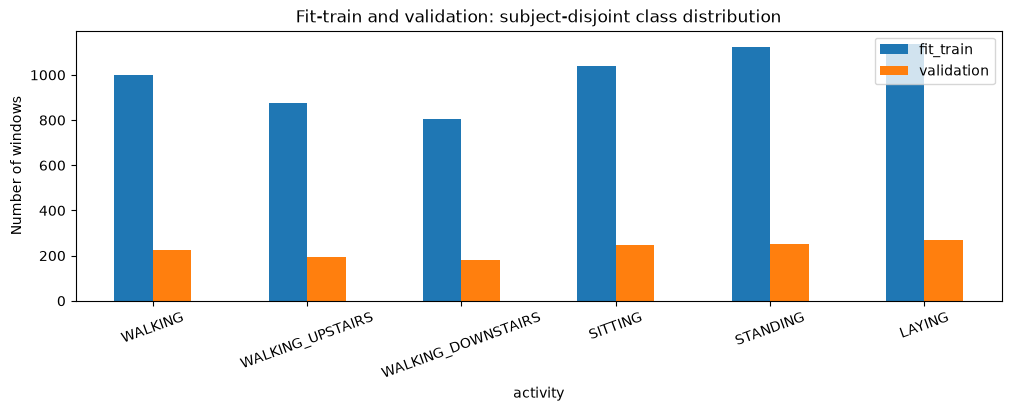

In [10]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
distribution.plot.bar(ax=ax, rot=20)
ax.set(ylabel="Number of windows", title="Fit-train and validation: subject-disjoint class distribution")
plt.show()
plt.close(fig)

### 3.1. Baseline và chỉ số đánh giá

Baseline luôn dự đoán lớp phổ biến nhất của fit-train. Đây là mốc tối thiểu, chưa đại diện cho SVM hoặc các phương pháp truyền thống mạnh. Báo cáo Accuracy, Macro-F1 (trung bình F1 đủ sáu lớp), Recall từng lớp và confusion matrix. Mean ± SD là thống kê qua seed, SD mẫu với `ddof=1`.

In [11]:
baseline_class = int(np.bincount(y_fit, minlength=6).argmax())
baseline_predictions = np.full_like(y_val, baseline_class)
baseline_val = calculate_metrics(y_val, baseline_predictions)
print("Baseline fit-train class:", ACTIVITIES[baseline_class])
display(pd.DataFrame([{"split":"validation", "accuracy":baseline_val["accuracy"], "macro_f1":baseline_val["macro_f1"]}]))

Baseline fit-train class: LAYING


,split,accuracy,macro_f1
0,validation,0.19562,0.054538


## 4. Kiến trúc và huấn luyện CNN-A/B/C

| Mô hình | Phần tích chập | Tham số |
|---|---|---:|
| CNN-A | Conv64/k5 → Pool2 | 7.494 |
| CNN-B | Conv64/k5 → Pool2 → Conv128/k3 | 36.294 |
| CNN-C | Conv64/k5 → Pool2 → Conv128/k3 → Conv128/k3 | 85.574 |

Conv dùng ReLU và padding same. Phần cuối chung: GAP → Dense64 ReLU → Dropout0,3 → Softmax6. Tăng độ sâu cũng đổi số tham số và receptive field; không coi đây là thí nghiệm cô lập riêng độ sâu.

Adam 0,001, batch 64, tối đa 50 epoch. Early stopping theo validation loss với patience 8; nạp lại checkpoint có loss thấp nhất. Khởi tạo lại mô hình/optimizer cho mỗi seed 42, 123, 2026. Chỉ xáo trộn fit-train.

In [12]:
def build_cnn(name):
    if name not in {"cnn_a", "cnn_b", "cnn_c"}:
        raise ValueError("Mô hình phải là cnn_a, cnn_b hoặc cnn_c")
    layers = tf.keras.layers
    model = tf.keras.Sequential(name=name)
    model.add(layers.Input(shape=(128, 9)))
    model.add(layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"))
    model.add(layers.MaxPooling1D(pool_size=2))
    if name in {"cnn_b", "cnn_c"}:
        model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    if name == "cnn_c":
        model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.GlobalAveragePooling1D())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(DROPOUT))
    model.add(layers.Dense(6, activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_sensor_cnn(n_channels):
    layers = tf.keras.layers
    model = tf.keras.Sequential(name="cnn_b_sensor")
    model.add(layers.Input(shape=(128, n_channels)))
    model.add(layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"))
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.GlobalAveragePooling1D())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(DROPOUT))
    model.add(layers.Dense(6, activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [13]:
tf.keras.utils.set_random_seed(42)
example_model = build_cnn("cnn_b")
example_model.summary()

Model: "cnn_b"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,294 (141.77 KB)

 Trainable params: 36,294 (141.77 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
def make_tf_dataset(x, labels, seed, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 2
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)


def make_callbacks(folder):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(str(folder / "model.keras"), monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.CSVLogger(str(folder / "history.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ]

### 4.1. Vòng huấn luyện trực tiếp

`inspect` bỏ qua `fit()` và đọc chín lượt tham chiếu. `smoke` chạy CNN-B seed42 một epoch. `train` chạy các cấu hình/seed đã chọn vào thư mục mới; không ghi đè hiện vật gốc. Các lượt tái chạy chỉ tính validation và không thay thế kết quả test đã khóa.

In [15]:
if RUN_MODE == "inspect":
    print("Chế độ inspect: không gọi model.fit(), đang đọc lịch sử có sẵn ở phần sau.")
else:
    run_root = validate_output(NEW_RUN_ROOT, OUTPUT_BASE, SOURCE_RESULTS)
    chosen_models = ["cnn_b"] if RUN_MODE == "smoke" else MODELS
    chosen_seeds = [42] if RUN_MODE == "smoke" else SEEDS
    if not chosen_models or len(set(chosen_models)) != len(chosen_models) or any(name not in {"cnn_a", "cnn_b", "cnn_c"} for name in chosen_models):
        raise ValueError("MODELS cần là danh sách hợp lệ, không trùng lặp")
    validate_seeds(chosen_seeds)
    reserve_research_run(NEW_RUN_ROOT, STUDY_ROOT, OUTPUT_BASE, SOURCE_RESULTS)
    create_run_folder(run_root)  # Từ chối cả đợt nếu RUN_NAME đã tồn tại.
    notebook_path = ROOT / "notebooks" / "HAR_Research.ipynb"
    source_snapshot_sha256 = None
    if notebook_path.is_file():
        snapshot_path = run_root / "notebook_source.ipynb"
        snapshot_path.write_bytes(notebook_path.read_bytes())
        source_snapshot_sha256 = sha256_file(snapshot_path)
    else:
        print("Không tìm thấy notebook trên đĩa để snapshot; lưu notebook và giữ mã cùng kết quả.")
    np.savez(run_root / "normalization.npz", mean=mean, std=std, channels=np.array(CHANNELS))
    save_json(run_root / "split.json", {
        "fit_train_indices_in_official_train": fit_indices.tolist(),
        "validation_indices_in_official_train": validation_indices.tolist(),
        "validation_subjects": VALIDATION_SUBJECTS,
    })
    source_paths = signal_files + [train_dir / "y_train.txt", train_dir / "subject_train.txt"]
    save_json(run_root / "experiment.json", {
        "mode": RUN_MODE, "models": chosen_models, "seeds": chosen_seeds,
        "kind": "smoke" if RUN_MODE == "smoke" else "notebook_reproduction",
        "test_evaluated": False, "started_utc": datetime.now(timezone.utc).isoformat(),
        "notebook_on_disk_sha256": source_snapshot_sha256,
        "snapshot_scope": "Notebook saved on disk; runtime model/seed/hyperparameters recorded separately",
        "python": sys.version, "tensorflow": tf.__version__, "numpy": np.__version__,
        "devices": [str(device) for device in tf.config.list_physical_devices()],
        "input_sha256": {p.relative_to(DATA_DIR).as_posix(): sha256_file(p) for p in source_paths},
    })
    for model_name in chosen_models:
        for seed in chosen_seeds:
            print(f"\n--- {model_name}, seed {seed}, mode {RUN_MODE} ---")
            folder = run_root / ("smoke" if RUN_MODE == "smoke" else "runs") / f"{model_name}_seed{seed}"
            create_run_folder(folder)
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)
            model = build_cnn(model_name)
            epochs = 1 if RUN_MODE == "smoke" else MAX_EPOCHS
            config = {
                "model": model_name, "seed": seed, "batch_size": BATCH_SIZE, "epochs_max": epochs,
                "learning_rate": LEARNING_RATE, "patience": PATIENCE, "dropout_rate": DROPOUT,
                "channels": CHANNELS, "parameters": model.count_params(), "test_evaluated": False,
            }
            save_json(folder / "config.json", config)
            (folder / "architecture.json").write_text(model.to_json(), encoding="utf-8")
            started = time.perf_counter()
            history = model.fit(
                make_tf_dataset(x_fit, y_fit, seed, training=True),
                validation_data=make_tf_dataset(x_val, y_val, seed),
                epochs=epochs,
                callbacks=make_callbacks(folder),
                shuffle=False,  # Dataset đã tự xáo trộn fit-train phía trên.
                verbose=2,
            )
            training_seconds = time.perf_counter() - started
            if not all(np.isfinite(v) for values in history.history.values() for v in values):
                raise ValueError("Lịch sử có NaN/Inf; không đưa lượt này vào bảng kết quả")
            # Luôn lấy checkpoint val_loss tốt nhất, không lấy mặc định epoch cuối.
            best_model = tf.keras.models.load_model(folder / "model.keras")
            probabilities = best_model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
            in_memory = model.predict(x_val[:64], batch_size=BATCH_SIZE, verbose=0)
            np.testing.assert_allclose(probabilities[:64], in_memory, rtol=1e-5, atol=1e-6)
            if not np.isfinite(probabilities).all() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
                raise ValueError("Xác suất validation không hợp lệ")
            predictions = probabilities.argmax(axis=1)
            metrics = {
                "model": model_name, "seed": seed, "split": "validation",
                "kind": "smoke" if RUN_MODE == "smoke" else "notebook_reproduction",
                "accuracy": float(accuracy_score(y_val, predictions)),
                "macro_f1": float(f1_score(y_val, predictions, labels=list(range(6)), average="macro", zero_division=0)),
                "epochs_run": len(history.history["loss"]),
                "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
                "parameters": model.count_params(), "training_seconds": training_seconds,
                "checkpoint_reload_verified": True, "test_evaluated": False,
                "report": classification_report(y_val, predictions, labels=list(range(6)), target_names=ACTIVITIES, output_dict=True, zero_division=0),
                "confusion_matrix": confusion_matrix(y_val, predictions, labels=list(range(6))).tolist(),
            }
            save_json(folder / "validation_metrics.json", metrics)
            frame = pd.DataFrame({"sample_index_in_official_train": validation_indices, "subject_id": subjects[validation_indices], "y_true": y_val, "y_pred": predictions})
            for index, activity in enumerate(ACTIVITIES):
                frame[f"p_{activity}"] = probabilities[:, index]
            frame.to_csv(folder / "validation_predictions.csv", index=False)
            save_json(folder / "checkpoint_sha256.json", {"model.keras": sha256_file(folder / "model.keras")})
            print(f"Validation Accuracy={metrics['accuracy']:.4f}, Macro-F1={metrics['macro_f1']:.4f}, time={training_seconds:.2f}s")

Chế độ inspect: không gọi model.fit(), đang đọc lịch sử có sẵn ở phần sau.


## 5. Kết quả kiến trúc và đánh giá test gốc

### 5.1. Kết quả validation và learning curves

Trong nghiên cứu gốc, cấu hình được chọn theo trung bình Macro-F1 validation; hòa tới bốn chữ số thập phân thì ưu tiên ít tham số hơn. Không chọn seed tốt nhất để đại diện phương pháp. Khi tái chạy, các bảng validation bên dưới thuộc đợt mới; quyết định và test tham chiếu ở mục sau vẫn thuộc đợt gốc.

In [16]:
if RUN_MODE == "inspect":
    run_folders = sorted((SOURCE_RESULTS / "runs").glob("cnn_*_seed*"))
else:
    run_folders = sorted((NEW_RUN_ROOT / ("smoke" if RUN_MODE == "smoke" else "runs")).glob("cnn_*_seed*"))
records = []
for folder in run_folders:
    path = folder / "validation_metrics.json"
    if path.exists():
        row = json.loads(path.read_text(encoding="utf-8"))
        records.append({key: row[key] for key in ("kind", "model", "seed", "split", "epochs_run", "best_epoch", "accuracy", "macro_f1", "parameters", "training_seconds")})
validation_table = pd.DataFrame(records)
if not validation_table.empty:
    display(validation_table.sort_values(["model", "seed"]))
    validation_summary = validation_table.groupby("model").agg(
        n_runs=("seed", "count"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    )
    display(validation_summary)
    print("SD là độ lệch chuẩn mẫu qua seed. Một lượt chạy có SD=NaN, không tự thay bằng 0.")
else:
    print("Chưa có lượt hoàn tất để hiển thị.")

,kind,model,seed,split,epochs_run,best_epoch,accuracy,macro_f1,parameters,training_seconds
2,official,cnn_a,42,validation,19,11,0.948905,0.952391,7494,30.281830
0,official,cnn_a,123,validation,17,9,0.942336,0.945840,7494,27.837602
1,official,cnn_a,2026,validation,19,11,0.945985,0.949958,7494,30.096381
5,official,cnn_b,42,validation,10,2,0.946715,0.950433,36294,22.560213
3,official,cnn_b,123,validation,20,12,0.957664,0.959491,36294,47.481765
4,official,cnn_b,2026,validation,16,8,0.946715,0.950584,36294,35.372130
8,official,cnn_c,42,validation,11,3,0.937226,0.939245,85574,70.193922
6,official,cnn_c,123,validation,11,3,0.950365,0.954048,85574,59.272066
7,official,cnn_c,2026,validation,10,2,0.952555,0.956242,85574,85.892310


,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
model,,,,,
cnn_a,3,0.945742,0.003291,0.949397,0.003311
cnn_b,3,0.950365,0.006321,0.953502,0.005187
cnn_c,3,0.946715,0.008290,0.949845,0.009245


SD là độ lệch chuẩn mẫu qua seed. Một lượt chạy có SD=NaN, không tự thay bằng 0.


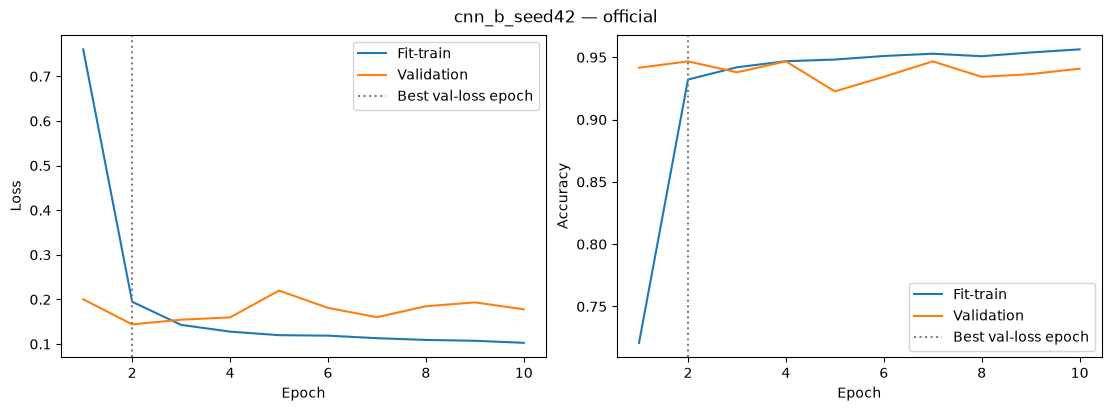

Checkpoint: E:\PPNCKH\SGU26_PPNCKH_Group\results\runs\cnn_b_seed42\model.keras


In [17]:
completed = [folder for folder in run_folders if (folder / "validation_metrics.json").exists()]
if completed:
    # Ưu tiên CNN-B seed 42 để minh họa theo quy ước của đồ án.
    preferred = next((folder for folder in completed if folder.name == "cnn_b_seed42"), completed[0])
    history_frame = pd.read_csv(preferred / "history.csv")
    saved_metrics = json.loads((preferred / "validation_metrics.json").read_text(encoding="utf-8"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history_frame["epoch"] + 1, history_frame[metric], marker="." if len(history_frame) == 1 else None, label="Fit-train")
        ax.plot(history_frame["epoch"] + 1, history_frame[f"val_{metric}"], marker="." if len(history_frame) == 1 else None, label="Validation")
        ax.axvline(saved_metrics["best_epoch"], color="gray", linestyle=":", label="Best val-loss epoch")
        ax.set(xlabel="Epoch", ylabel=metric.capitalize())
        ax.legend()
    fig.suptitle(f"{preferred.name} — {saved_metrics['kind']}")
    plt.show()
    if RUN_MODE != "inspect":
        fig.savefig(preferred / "learning_curves.png", dpi=180)
    plt.close(fig)
    print("Checkpoint:", preferred / "model.keras")

### 5.2. Khóa lựa chọn trước test và kết quả cuối

Đợt gốc đã khóa đủ chín checkpoint và chọn CNN-B trước khi xem test. Không huấn luyện lại trên toàn bộ official train. Ô sau xác minh tệp, tính lại chỉ số từ CSV và hiển thị số liệu tham chiếu; **không chạy suy luận test**, kể cả khi notebook đang tái chạy huấn luyện.

Các test cũ đã được xem trước khi thiết kế nghiên cứu cảm biến ở mục 7. Vì vậy phần mở rộng phải được gọi là nghiên cứu khám phá.

Original experiment: {'state': 'verified', 'runs': 9, 'test_windows_per_run': 2947, 'selected_model': 'cnn_b'}
Selected before test: cnn_b


,model,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,training_seconds_mean
0,cnn_a,3,0.945742,0.003291,0.949397,0.003311,7494,29.405271
1,cnn_b,3,0.950365,0.006321,0.953502,0.005187,36294,35.138036
2,cnn_c,3,0.946715,0.008290,0.949845,0.009245,85574,71.786099


,model,seed,split,accuracy,macro_f1,parameters,training_seconds,epochs_run,best_epoch
0,cnn_a,42,test,0.910417,0.911631,7494,30.281830,19,11
1,cnn_a,123,test,0.904649,0.905878,7494,27.837602,17,9
2,cnn_a,2026,test,0.905667,0.907147,7494,30.096381,19,11
3,cnn_b,42,test,0.910078,0.910806,36294,22.560213,10,2
4,cnn_b,123,test,0.917543,0.918174,36294,47.481765,20,12
5,cnn_b,2026,test,0.918222,0.919264,36294,35.372130,16,8
6,cnn_c,42,test,0.913471,0.913749,85574,70.193922,11,3
7,cnn_c,123,test,0.912114,0.912320,85574,59.272066,11,3
8,cnn_c,2026,test,0.912114,0.912013,85574,85.892310,10,2


,model,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,training_seconds_mean
0,cnn_a,3,0.906911,0.003079,0.908219,0.003023,7494,29.405271
1,cnn_b,3,0.915281,0.004519,0.916081,0.004601,36294,35.138036
2,cnn_c,3,0.912566,0.000784,0.912694,0.000926,85574,71.786099


Baseline test: 0.18221920597217509 0.05137772675086108


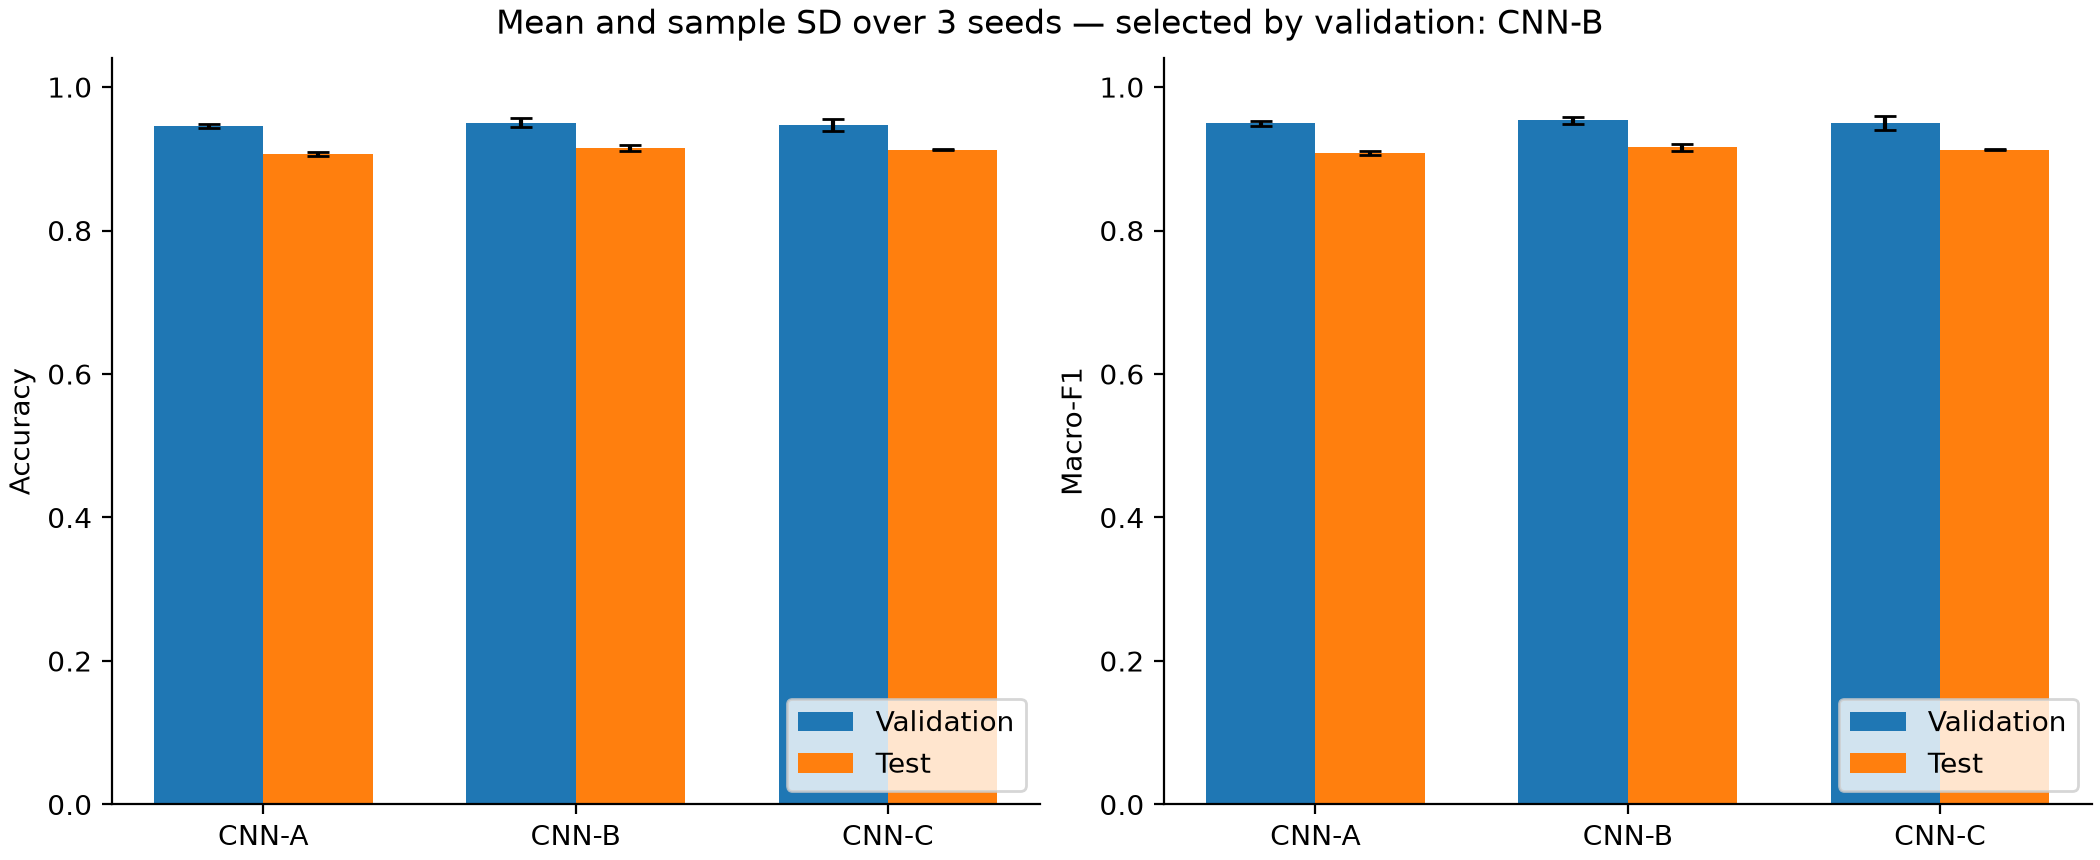

In [18]:
from har_project.finalization import verify_results
verification = verify_results(SOURCE_RESULTS)
print("Original experiment:", verification)
original_lock = json.loads((SOURCE_RESULTS / "protocol_lock.json").read_text(encoding="utf-8"))
print("Selected before test:", original_lock["selected_model"])
original_validation = pd.read_csv(SOURCE_RESULTS / "validation_metrics_summary.csv")
original_test = pd.read_csv(SOURCE_RESULTS / "metrics_summary.csv")
original_runs = pd.read_csv(SOURCE_RESULTS / "metrics_per_run.csv")
display(original_validation)
display(original_runs)
display(original_test)
baseline_test = json.loads((SOURCE_RESULTS / "baseline_test_metrics.json").read_text(encoding="utf-8"))
print("Baseline test:", baseline_test["accuracy"], baseline_test["macro_f1"])
from IPython.display import Image, display
display(Image(filename=str(ROOT / "report/figures/model_comparison.png")))

### 5.3. Diễn giải kết quả gốc

CNN-B đạt Accuracy test trung bình **91,53%**, Macro-F1 **0,9161**. CNN-C có nhiều tham số hơn nhưng không có điểm trung bình cao hơn CNN-B trong thiết lập này. Baseline lớp nằm đạt Accuracy 18,22% và Macro-F1 0,0514; vượt baseline này chưa chứng minh CNN vượt các baseline truyền thống mạnh.

Chênh lệch validation/test cần xem cùng sự khác biệt người tham gia. Chênh lệch với bài báo gốc còn liên quan đến đầu vào, kiến trúc, optimizer và lượng dữ liệu fit-train; chưa thể quy về một nguyên nhân riêng.

## 6. Người mới và lỗi ngồi–đứng

### 6.1. Người mới có được nhận dạng tốt không?

Đọc dự đoán test cũ của cả ba seed CNN-B và kiểm tra hash, thứ tự cửa sổ, nhãn, người và xác suất. Đánh giá từng người để tránh che khuất chênh lệch bằng một điểm trung bình.

,samples,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
subject_id,,,,,
2,302,0.895143,0.001912,0.874721,0.002953
4,317,0.891693,0.027561,0.884805,0.037590
9,288,0.803241,0.028066,0.761616,0.040793
10,294,0.718821,0.018733,0.703821,0.015816
12,320,0.973958,0.024273,0.973332,0.024219
13,327,0.970438,0.009343,0.968780,0.010021
18,364,0.965201,0.003172,0.965730,0.003470
20,354,0.962335,0.008155,0.967288,0.007246
24,381,0.999125,0.001515,0.999050,0.001645


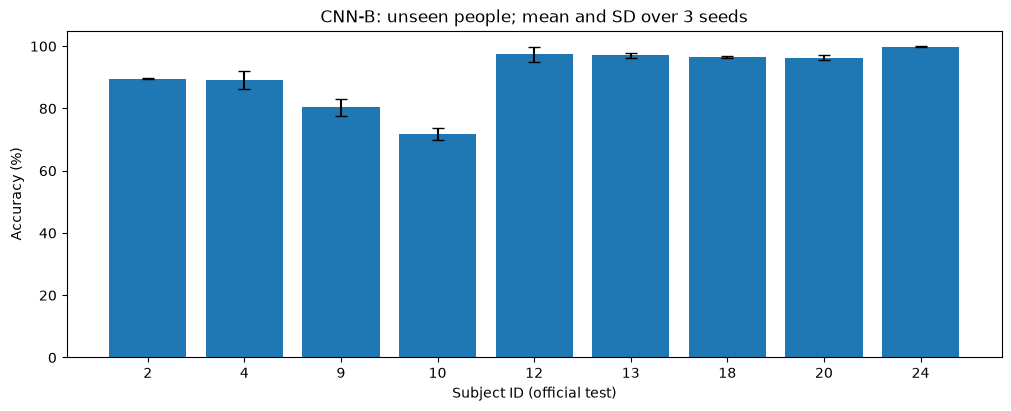

In [19]:
status = json.loads((SOURCE_RESULTS / "test_evaluation_status.json").read_text(encoding="utf-8"))
if status.get("state") != "completed" or status.get("lock_sha256") != sha256_file(SOURCE_RESULTS / "protocol_lock.json"):
    raise ValueError("Kết quả gốc chưa hoàn tất hoặc lock thay đổi")
archived_frames, person_rows, error_rows, archived_input_hashes = {}, [], [], {}
reference_rows = None
for seed in [42, 123, 2026]:
    relative = f"runs/cnn_b_seed{seed}/test_predictions.csv"
    path = SOURCE_RESULTS / relative
    expected = status["result_sha256"].get(relative)
    if expected != sha256_file(path):
        raise ValueError(f"Dự đoán test gốc đã thay đổi: {relative}")
    archived_input_hashes[relative] = expected
    frame = validate_predictions(pd.read_csv(path), "sample_index")
    alignment = frame[["sample_index", "subject_id", "y_true"]].to_numpy()
    if reference_rows is None:
        reference_rows = alignment
    elif not np.array_equal(reference_rows, alignment):
        raise ValueError("Các seed không cùng thứ tự mẫu test")
    archived_frames[seed] = frame
    metrics = calculate_metrics(frame.y_true, frame.y_pred)
    error_rows.append({"seed": seed, **{k: metrics[k] for k in ["accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors", "recall_SITTING", "recall_STANDING"]}})
    for person, part in frame.groupby("subject_id"):
        m = calculate_metrics(part.y_true, part.y_pred)
        person_rows.append({"seed": seed, "subject_id": int(person), "samples": len(part), "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
person_table = pd.DataFrame(person_rows)
person_summary = person_table.groupby("subject_id").agg(samples=("samples", "first"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"), macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"))
error_table = pd.DataFrame(error_rows)
display(person_summary)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(person_summary.index.astype(str), person_summary.accuracy_mean*100, yerr=person_summary.accuracy_std*100, capsize=4)
ax.set(xlabel="Subject ID (official test)", ylabel="Accuracy (%)", ylim=(0, 105), title="CNN-B: unseen people; mean and SD over 3 seeds")
archived_subject_figure = fig

### 6.2. Ngồi và đứng bị nhầm như thế nào?

Bảng lỗi dùng cả ba seed; confusion matrix dùng seed42 đã định trước. Hình tín hiệu lấy cửa sổ đầu tiên của mỗi lớp ở validation ID5 theo quy tắc cố định. Chúng không phải chính các mẫu test bị nhầm. Phân phối tín hiệu dùng official train, chỉ mô tả dữ liệu và gợi ý giả thuyết; không chứng minh cơ chế gây lỗi của mô hình.

,seed,accuracy,macro_f1,sit_stand_errors,sitting_to_standing,standing_to_sitting,total_errors,recall_SITTING,recall_STANDING
0,42,0.910078,0.910806,197,104,93,265,0.769857,0.825188
1,123,0.917543,0.918174,190,120,70,243,0.739308,0.866541
2,2026,0.918222,0.919264,189,81,108,241,0.792261,0.795113


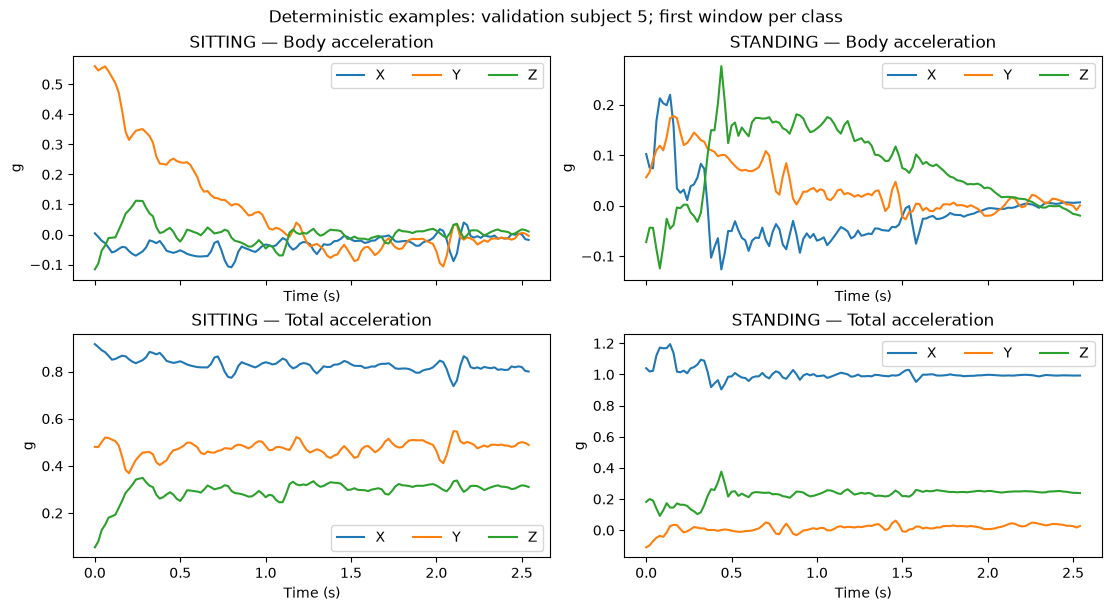

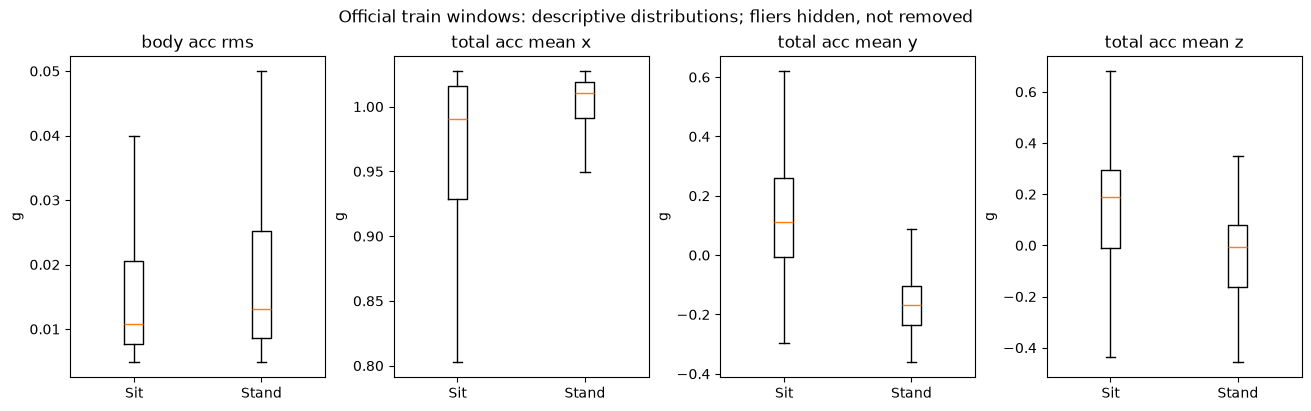

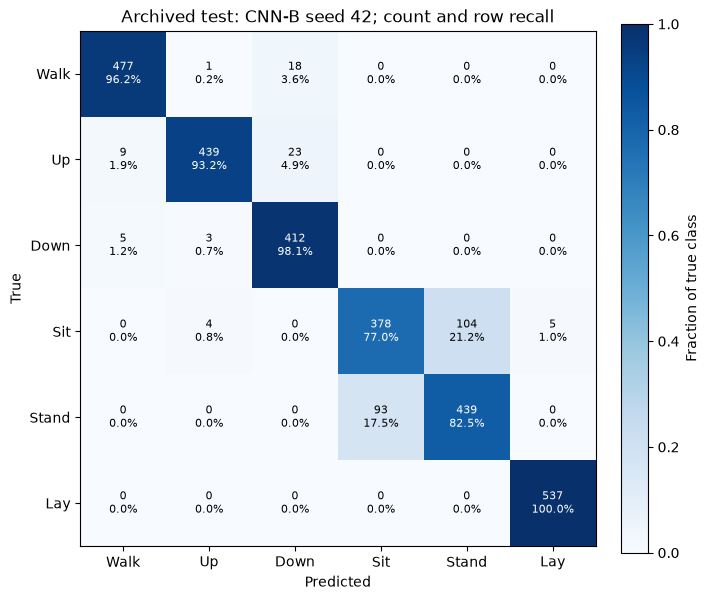

In [20]:
if set(subjects.tolist()) & set(archived_frames[42].subject_id.tolist()):
    raise ValueError("Trùng người official train/test")
example_indices = {label: int(np.flatnonzero((subjects == 5) & (y == label))[0]) for label in [3, 4]}
time_axis = np.arange(128) / 50
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, layout="constrained")
for col, label in enumerate([3, 4]):
    idx = example_indices[label]
    for row, (indices, title) in enumerate([([0,1,2], "Body acceleration"), ([6,7,8], "Total acceleration")]):
        for channel, axis_name in zip(indices, "XYZ"):
            axes[row, col].plot(time_axis, X[idx, :, channel], label=axis_name)
        axes[row, col].set(title=f"{ACTIVITIES[label]} — {title}", ylabel="g", xlabel="Time (s)")
        axes[row, col].legend(ncols=3)
fig.suptitle("Deterministic examples: validation subject 5; first window per class")
signal_figure = fig

feature_table = pd.DataFrame({
    "sample_index_in_official_train": np.arange(len(y)), "subject_id": subjects, "activity": [ACTIVITIES[i] for i in y],
    "body_acc_rms": np.sqrt(np.mean(np.sum(X[:,:,:3].astype(float)**2, axis=2), axis=1)),
    **{f"total_acc_mean_{axis}": X[:,:,6+i].mean(axis=1) for i,axis in enumerate("xyz")},
})
static = feature_table[feature_table.activity.isin(["SITTING", "STANDING"])]
fig, axes = plt.subplots(1, 4, figsize=(13, 4), layout="constrained")
for ax, feature in zip(axes, ["body_acc_rms", "total_acc_mean_x", "total_acc_mean_y", "total_acc_mean_z"]):
    ax.boxplot([static.loc[static.activity == name, feature] for name in ["SITTING", "STANDING"]], tick_labels=["Sit", "Stand"], showfliers=False)
    ax.set(title=feature.replace("_", " "), ylabel="g")
fig.suptitle("Official train windows: descriptive distributions; fliers hidden, not removed")
feature_figure = fig
display(error_table)
cm = np.asarray(calculate_metrics(archived_frames[42].y_true, archived_frames[42].y_pred)["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), vmin=0, vmax=1, cmap="Blues")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i,j]}\n{cm[i,j]/cm[i].sum():.1%}", ha="center", va="center", color="white" if cm[i,j]/cm[i].sum() > .5 else "black", fontsize=8)
ax.set(xticks=range(6), yticks=range(6), xticklabels=["Walk","Up","Down","Sit","Stand","Lay"], yticklabels=["Walk","Up","Down","Sit","Stand","Lay"], xlabel="Predicted", ylabel="True", title="Archived test: CNN-B seed 42; count and row recall")
fig.colorbar(im, ax=ax, label="Fraction of true class")
confusion_figure = fig

## 7. Vai trò của các nhóm cảm biến

### 7.1. Thiết kế khảo sát đầu vào

| Biểu diễn | Kênh |
|---|---|
| total_acc | Gia tốc tổng X/Y/Z |
| gyro | Con quay X/Y/Z |
| total_acc_gyro | Gia tốc tổng + con quay |
| body_acc_gyro | Gia tốc cơ thể + con quay |
| all_9 | Gia tốc cơ thể + con quay + gia tốc tổng |

Giữ nguyên CNN-B, split và lịch huấn luyện, chạy ba seed cho mỗi biểu diễn. Số tham số lớp đầu thay đổi nhẹ theo đầu vào; cùng seed không bảo đảm cùng trọng số ban đầu khi kích thước khác nhau. Không đo mức tiêu thụ pin.

Thực nghiệm tham chiếu đã chạy đủ 15 lượt. Chuẩn hóa mỗi nhóm bằng fit-train. Validation cũng được dùng cho early stopping, nên điểm khảo sát là điểm phát triển trên một split; chưa có test độc lập mới.

In [21]:
STUDY_ROOT = validate_location(STUDY_ROOT, STUDY_OUTPUT_BASE, SOURCE_RESULTS)
if RUN_MODE == "inspect":
    manifest = json.loads((STUDY_ROOT / "manifest.json").read_text(encoding="utf-8"))
    if manifest.get("state") != "completed":
        raise ValueError("Nghiên cứu chưa hoàn tất")
    actual_paths = {p.relative_to(STUDY_ROOT).as_posix() for p in STUDY_ROOT.rglob("*") if p.is_file() and p.name != "manifest.json"}
    if actual_paths != set(manifest["sha256"]):
        raise ValueError("Danh sách hiện vật không khớp manifest")
    for relative, expected in manifest["sha256"].items():
        path = (STUDY_ROOT / relative).resolve()
        if not path.is_relative_to(STUDY_ROOT) or sha256_file(path) != expected:
            raise ValueError(f"Hiện vật thay đổi: {relative}")
    archived_config = json.loads((STUDY_ROOT / "experiment.json").read_text(encoding="utf-8"))
    print("Đã xác minh", len(manifest["sha256"]), "hiện vật.")

Đã xác minh 114 hiện vật.


### 7.2. Huấn luyện khảo sát cảm biến

Đây là vòng `model.fit()` thứ hai, dùng các nhóm kênh thay cho thay đổi độ sâu. `inspect` xác minh bộ 15 lượt có sẵn; `smoke` chỉ chạy all_9/seed42 một epoch. Mọi đầu ra mới tách khỏi bộ tham chiếu.

In [22]:
is_smoke_study = RUN_MODE == "smoke" or (RUN_MODE == "inspect" and archived_config.get("kind") == "smoke")
chosen_groups = ["all_9"] if is_smoke_study else list(GROUPS)
chosen_seeds = [42] if is_smoke_study else SEEDS
validate_seeds(chosen_seeds)
run_config = {
    "kind": "smoke" if is_smoke_study else "post_test_exploratory_validation",
    "groups": {name: GROUPS[name] for name in chosen_groups}, "seeds": chosen_seeds,
    "validation_subjects": VALIDATION_SUBJECTS, "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE, "epochs_max": 1 if is_smoke_study else MAX_EPOCHS,
    "patience": PATIENCE, "dropout": DROPOUT, "new_test_inference": False,
}
source_paths = signal_files + [train_dir / "y_train.txt", train_dir / "subject_train.txt"]
input_hashes = {p.relative_to(DATA_DIR).as_posix(): sha256_file(p) for p in source_paths}
if RUN_MODE == "inspect":
    for key, value in run_config.items():
        if archived_config.get(key) != value:
            raise ValueError(f"Cấu hình không khớp đợt đã lưu: {key}")
    if input_hashes != archived_config["train_input_sha256"] or archived_input_hashes != archived_config["archived_prediction_sha256"]:
        raise ValueError("Dữ liệu đầu vào thay đổi")
    print("Inspect: không gọi fit hoặc ghi hiện vật.")
else:
    reserve_output(STUDY_ROOT, STUDY_OUTPUT_BASE, SOURCE_RESULTS)
    (STUDY_ROOT / "figures").mkdir()
    snapshot = STUDY_ROOT / "notebook_source.ipynb"
    snapshot.write_bytes((ROOT / "notebooks/HAR_Research.ipynb").read_bytes())
    protocol = ROOT / "docs/research/practical-questions.md"
    (STUDY_ROOT / "protocol.md").write_bytes(protocol.read_bytes())
    save_json(STUDY_ROOT / "experiment.json", {
        **run_config, "started_utc": datetime.now(timezone.utc).isoformat(),
        "python": sys.version, "tensorflow": tf.__version__, "numpy": np.__version__,
        "packages": {name: importlib.metadata.version(name) for name in ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel"]},
        "runtime": {"deterministic_ops_requested": True, "intra_op_threads": tf.config.threading.get_intra_op_parallelism_threads(),
            "inter_op_threads": tf.config.threading.get_inter_op_parallelism_threads(), "dataset_private_threads": 2,
            "dataset_max_intra_op_threads": 2, "TF_ENABLE_ONEDNN_OPTS": os.environ.get("TF_ENABLE_ONEDNN_OPTS")},
        "platform": platform.platform(), "devices": [str(d) for d in tf.config.list_physical_devices()],
        "train_input_sha256": input_hashes, "archived_prediction_sha256": archived_input_hashes,
        "notebook_on_disk_sha256": sha256_file(snapshot), "protocol_sha256": sha256_file(protocol),
        "snapshot_scope": "Saved notebook on disk; actual execution configuration recorded in this file and each config.json",
    })
    save_json(STUDY_ROOT / "split.json", {"fit_indices": fit_indices.tolist(), "validation_indices": validation_indices.tolist(),
        "fit_subjects": np.unique(subjects[fit_indices]).tolist(), "validation_subjects": VALIDATION_SUBJECTS,
        "examples_in_official_train": {ACTIVITIES[k]: v for k,v in example_indices.items()}})
    for group in chosen_groups:
        a, b, mean, std = prepare_channels(x_fit_raw, x_val_raw, group)
        group_root = STUDY_ROOT / "runs" / group
        group_root.mkdir(parents=True)
        np.savez(group_root / "normalization.npz", mean=mean, std=std, channel_indices=GROUPS[group])
        for seed in chosen_seeds:
            folder = group_root / f"seed{seed}"
            folder.mkdir()
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)
            model = build_sensor_cnn(a.shape[-1])
            save_json(folder / "config.json", {**run_config, "group": group, "seed": seed, "channel_indices": GROUPS[group], "parameters": model.count_params()})
            (folder / "architecture.json").write_text(model.to_json(), encoding="utf-8")
            print(f"Training {group}, seed {seed}", flush=True)
            started = time.perf_counter()
            history = model.fit(
                make_tf_dataset(a, y_fit, seed, training=True),
                validation_data=make_tf_dataset(b, y_val, seed),
                epochs=run_config["epochs_max"], callbacks=make_callbacks(folder), shuffle=False, verbose=0,
            )
            seconds = time.perf_counter() - started
            if not all(np.isfinite(v) for values in history.history.values() for v in values):
                raise ValueError("Lịch sử có giá trị không hữu hạn")
            best = tf.keras.models.load_model(folder / "model.keras")
            probabilities = np.asarray(best.predict(b, batch_size=BATCH_SIZE, verbose=0))
            np.testing.assert_allclose(probabilities[:64], model.predict(b[:64], verbose=0), rtol=1e-5, atol=1e-6)
            frame = pd.DataFrame({"sample_index_in_official_train": validation_indices, "subject_id": subjects[validation_indices], "y_true": y_val, "y_pred": probabilities.argmax(axis=1)})
            for i, name in enumerate(ACTIVITIES): frame["p_"+name] = probabilities[:,i]
            validate_predictions(frame, "sample_index_in_official_train")
            frame.to_csv(folder / "validation_predictions.csv", index=False)
            metrics = {**calculate_metrics(y_val, frame.y_pred), "group": group, "seed": seed,
                "kind": run_config["kind"], "split": "validation", "new_test_inference": False,
                "parameters": model.count_params(), "training_seconds": seconds,
                "epochs_run": len(history.history["loss"]), "best_epoch": int(np.argmin(history.history["val_loss"])+1),
                "checkpoint_reload_verified": True, "checkpoint_sha256": sha256_file(folder / "model.keras")}
            save_json(folder / "validation_metrics.json", metrics)
            print(f"  Macro-F1={metrics['macro_f1']:.4f}, Accuracy={metrics['accuracy']:.4f}, {seconds:.1f}s", flush=True)

Inspect: không gọi fit hoặc ghi hiện vật.


### 7.3. Tổng hợp và so sánh cùng seed

Tính lại chỉ số từng lượt từ CSV. So sánh thêm con quay, thêm gia tốc tổng và thêm gia tốc cơ thể bằng chênh lệch ghép cùng seed. Số lỗi ngồi–đứng thấp chưa đủ để kết luận tốt hơn: mô hình có thể nhầm những mẫu đó sang lớp khác.

,group,seed,accuracy,macro_f1,sit_stand_errors,sitting_to_standing,standing_to_sitting,total_errors,parameters,training_seconds,epochs_run,best_epoch,recall_WALKING,recall_WALKING_UPSTAIRS,recall_WALKING_DOWNSTAIRS,recall_SITTING,recall_STANDING,recall_LAYING
0,total_acc,42,0.909489,0.911371,53,10,43,124,34374,43.491106,16,8,1.000000,0.795918,1.000000,0.834677,0.828,1.000000
1,total_acc,123,0.937226,0.938784,45,10,35,86,34374,59.323583,20,12,0.942478,0.933673,1.000000,0.899194,0.860,1.000000
2,total_acc,2026,0.897810,0.898406,51,8,43,140,34374,27.473508,12,4,0.823009,0.923469,1.000000,0.830645,0.828,1.000000
3,gyro,42,0.755474,0.768176,35,13,22,335,34374,93.808802,27,19,0.699115,0.948980,0.967033,0.709677,0.756,0.559701
4,gyro,123,0.745985,0.763290,66,9,57,348,34374,99.211106,33,25,0.884956,0.933673,0.928571,0.814516,0.604,0.436567
5,gyro,2026,0.768613,0.777370,63,13,50,317,34374,125.290505,41,33,0.845133,0.948980,0.972527,0.911290,0.712,0.354478
6,total_acc_gyro,42,0.924088,0.926910,51,8,43,104,35334,50.505795,16,8,0.933628,0.959184,1.000000,0.846774,0.828,1.000000
7,total_acc_gyro,123,0.930657,0.932811,52,9,43,95,35334,37.479535,12,4,0.920354,0.964286,1.000000,0.891129,0.828,1.000000
8,total_acc_gyro,2026,0.922628,0.923330,51,8,43,106,35334,51.221378,16,8,0.907080,0.913265,1.000000,0.899194,0.828,1.000000
9,body_acc_gyro,42,0.929927,0.936561,32,11,21,96,35334,139.102621,44,36,1.000000,1.000000,1.000000,0.778226,0.900,0.940299


,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,sit_stand_errors_mean,training_seconds_mean
group,,,,,,,,
total_acc,3,0.914842,0.020246,0.916187,0.020615,34374,49.666667,43.429399
gyro,3,0.756691,0.011363,0.769612,0.007149,34374,54.666667,106.103471
total_acc_gyro,3,0.925791,0.004277,0.927684,0.004788,35334,51.333333,46.402236
body_acc_gyro,3,0.922871,0.006377,0.930556,0.005384,35334,35.333333,134.250937
all_9,3,0.950365,0.006321,0.953502,0.005187,36294,50.333333,42.517743


,baseline,candidate,seed,delta_macro_f1,delta_sit_stand_errors
0,total_acc,total_acc_gyro,42,0.015539,-2
1,total_acc,total_acc_gyro,123,-0.005973,7
2,total_acc,total_acc_gyro,2026,0.024924,0
3,body_acc_gyro,all_9,42,0.013871,19
4,body_acc_gyro,all_9,123,0.030545,11
5,body_acc_gyro,all_9,2026,0.024423,15
6,total_acc_gyro,all_9,42,0.023523,0
7,total_acc_gyro,all_9,123,0.026680,-6
8,total_acc_gyro,all_9,2026,0.027254,3


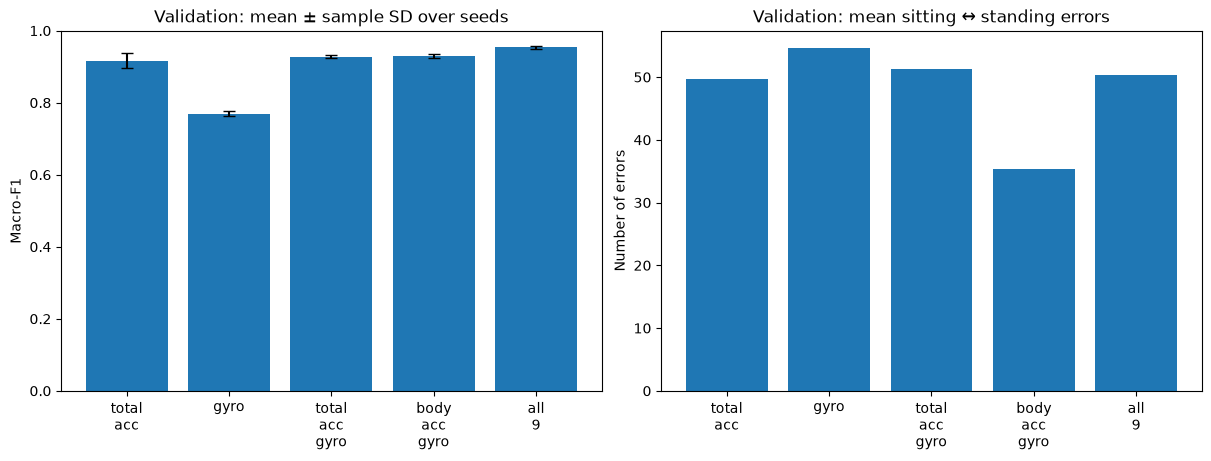

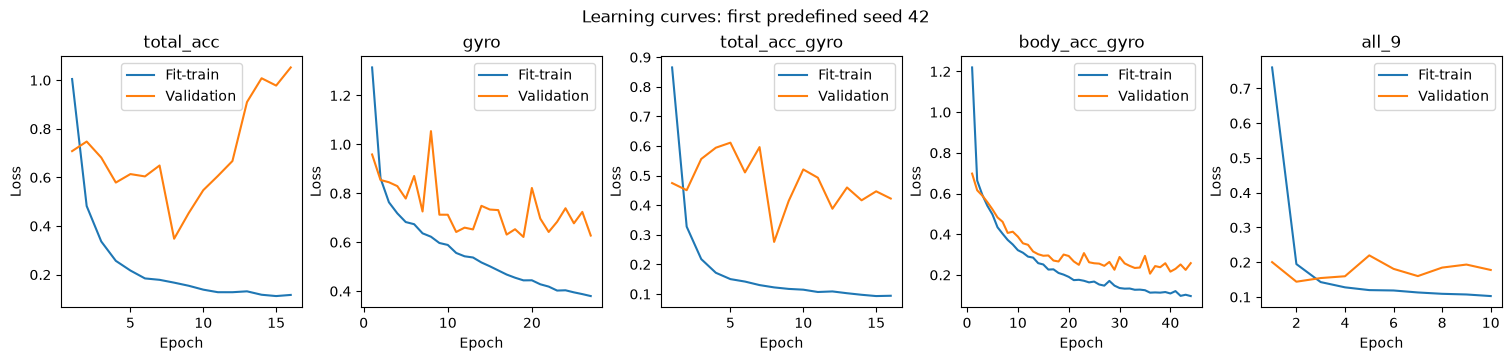

In [23]:
records, person_validation_rows = [], []
for group in chosen_groups:
    for seed in chosen_seeds:
        folder = STUDY_ROOT / "runs" / group / f"seed{seed}"
        stored = json.loads((folder / "validation_metrics.json").read_text(encoding="utf-8"))
        frame = validate_predictions(pd.read_csv(folder / "validation_predictions.csv"), "sample_index_in_official_train")
        if not np.array_equal(frame.sample_index_in_official_train, validation_indices) or not np.array_equal(frame.y_true, y_val) or not np.array_equal(frame.subject_id, subjects[validation_indices]):
            raise ValueError("Dự đoán validation không khớp split")
        recomputed = calculate_metrics(frame.y_true, frame.y_pred)
        for key in ["accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors"] + ["recall_"+a for a in ACTIVITIES]:
            if not np.isclose(stored[key], recomputed[key], atol=1e-12, rtol=0):
                raise ValueError(f"Metric không khớp CSV: {group}/{seed}/{key}")
        if stored["confusion_matrix"] != recomputed["confusion_matrix"]:
            raise ValueError("Confusion matrix không khớp")
        records.append({key: stored[key] for key in ["group", "seed", "accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors", "parameters", "training_seconds", "epochs_run", "best_epoch"] + ["recall_"+a for a in ACTIVITIES]})
        for person, part in frame.groupby("subject_id"):
            m = calculate_metrics(part.y_true, part.y_pred)
            person_validation_rows.append({"group": group, "seed": seed, "subject_id": int(person), "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
run_table = pd.DataFrame(records)
summary = run_table.groupby("group", sort=False).agg(n_runs=("seed", "count"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"), parameters=("parameters", "first"),
    sit_stand_errors_mean=("sit_stand_errors", "mean"), training_seconds_mean=("training_seconds", "mean"))
display(run_table)
display(summary)
contrasts = [("total_acc", "total_acc_gyro"), ("body_acc_gyro", "all_9"), ("total_acc_gyro", "all_9")]
paired_rows = []
for baseline, candidate in contrasts:
    if baseline not in chosen_groups or candidate not in chosen_groups: continue
    a = run_table[run_table.group == baseline].set_index("seed")
    b = run_table[run_table.group == candidate].set_index("seed")
    for seed in chosen_seeds:
        paired_rows.append({"baseline": baseline, "candidate": candidate, "seed": seed,
            "delta_macro_f1": b.loc[seed,"macro_f1"] - a.loc[seed,"macro_f1"],
            "delta_sit_stand_errors": int(b.loc[seed,"sit_stand_errors"] - a.loc[seed,"sit_stand_errors"])})
paired = pd.DataFrame(paired_rows, columns=["baseline", "candidate", "seed", "delta_macro_f1", "delta_sit_stand_errors"])
display(paired)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
labels = [g.replace("_", "\n") for g in summary.index]
axes[0].bar(labels, summary.macro_f1_mean, yerr=summary.macro_f1_std.fillna(0), capsize=4)
axes[0].set(ylabel="Macro-F1", ylim=(0, 1), title="Validation: mean ± sample SD over seeds")
axes[1].bar(labels, summary.sit_stand_errors_mean)
axes[1].set(ylabel="Number of errors", title="Validation: mean sitting ↔ standing errors")
sensor_figure = fig
fig, axes = plt.subplots(1, len(chosen_groups), figsize=(max(5, 3*len(chosen_groups)), 3.5), squeeze=False, layout="constrained")
for ax, group in zip(axes[0], chosen_groups):
    h = pd.read_csv(STUDY_ROOT / "runs" / group / f"seed{chosen_seeds[0]}" / "history.csv")
    ax.plot(h.epoch+1, h.loss, label="Fit-train")
    ax.plot(h.epoch+1, h.val_loss, label="Validation")
    ax.set(title=group, xlabel="Epoch", ylabel="Loss")
    ax.legend()
fig.suptitle(f"Learning curves: first predefined seed {chosen_seeds[0]}")
curves_figure = fig

## 8. Tổng hợp câu trả lời, thảo luận và kết luận

### 8.1. Câu trả lời tính từ bằng chứng

Các đoạn và bảng sau được tạo từ dự đoán đã lưu. Khi chạy mặc định inspect, đây là kết quả nghiên cứu đã thực hiện; khi tái chạy, phần cảm biến là kết quả validation của đợt mới, còn phân tích test vẫn là bộ test tham chiếu.

In [24]:
from IPython.display import Markdown
overall_acc = error_table.accuracy.mean()*100
low, high = person_summary.accuracy_mean.min()*100, person_summary.accuracy_mean.max()*100
fractions = error_table.sit_stand_errors / error_table.total_errors
lines = [
    "# Câu trả lời thực tế từ thực nghiệm HAR", "",
    "Nghiên cứu khám phá bổ sung sau khi đã xem test của protocol 1.0. Test cũ chỉ được đọc từ dự đoán lưu sẵn; thí nghiệm cảm biến mới chỉ đánh giá validation.", "",
    "## 1. Người mới có được nhận dạng tốt không?", "",
    f"CNN-B đạt Accuracy test trung bình {overall_acc:.2f}% qua ba seed trên cùng 9 người chưa xuất hiện trong huấn luyện. Accuracy trung bình theo từng người nằm trong khoảng {low:.2f}%–{high:.2f}%.", "",
    "**Cách giải thích:** mô hình có khả năng nhận dạng người mới trong bộ dữ liệu này, nhưng chất lượng không đồng đều. Điểm trung bình không bảo đảm mọi người đều đạt mức đó. Chưa có bằng chứng về điện thoại, vị trí đeo hoặc bối cảnh khác.", "",
    "## 2. Ngồi và đứng bị nhầm như thế nào?", "",
    f"Số lỗi ngồi–đứng hai chiều qua ba seed là {error_table.sit_stand_errors.tolist()}; chiếm {fractions.min():.1%}–{fractions.max():.1%} tổng lỗi của từng seed.", "",
    "**Cách giải thích:** đây là khó khăn nổi bật quan sát được. Khi ít chuyển động, gia tốc cơ thể có thể cung cấp ít dấu hiệu phân biệt; gia tốc tổng có thể bổ sung thông tin tư thế. Đây là giả thuyết cơ chế, không phải nguyên nhân đã được chứng minh. Hình ví dụ lấy từ validation, không phải cửa sổ test bị nhầm.", "",
    "## 3. Chỉ gia tốc kế có đủ không?", "",
    "Các điểm sau dùng cùng một validation gồm bốn người, cũng được dùng cho early stopping. Chúng chưa phải bằng chứng test độc lập:", "",
    "| Biểu diễn | Accuracy mean ± SD | Macro-F1 mean ± SD | Lỗi ngồi–đứng TB | Tham số |", "|---|---|---|---|---|",
]
for group, row in summary.iterrows():
    sd_acc = f"{row.accuracy_std*100:.2f}" if np.isfinite(row.accuracy_std) else "N/A"
    sd_f1 = f"{row.macro_f1_std:.4f}" if np.isfinite(row.macro_f1_std) else "N/A"
    lines.append(f"| {group} | {row.accuracy_mean*100:.2f}% ± {sd_acc} điểm % | {row.macro_f1_mean:.4f} ± {sd_f1} | {row.sit_stand_errors_mean:.1f} | {int(row.parameters):,} |")
lines += ["", "**So sánh ghép cùng seed:** giá trị dương của ΔMacro-F1 có lợi cho cấu hình bổ sung; giá trị âm của Δlỗi ngồi–đứng nghĩa là ít nhầm hơn.", ""]
for (baseline, candidate), part in paired.groupby(["baseline", "candidate"], sort=False):
    deltas = part.delta_macro_f1
    direction = "nhất quán tăng ở tất cả seed" if (deltas > 0).all() else "nhất quán giảm ở tất cả seed" if (deltas < 0).all() else "khác nhau theo seed hoặc có seed không đổi"
    lines.append(f"- {baseline} → {candidate}: ΔMacro-F1 trung bình {deltas.mean():+.4f}; khoảng qua seed [{deltas.min():+.4f}, {deltas.max():+.4f}], {direction}; Δlỗi ngồi–đứng trung bình {part.delta_sit_stand_errors.mean():+.1f}.")
lines += ["", "**Giới hạn:** số kênh cũng thay đổi tham số lớp đầu; cùng seed không bảo đảm cùng khởi tạo khi kích thước khác nhau. Không đo pin, không suy ra hiệu quả trên điện thoại thật, không khẳng định cảm biến nào luôn tốt nhất. Tổng gia tốc và gia tốc cơ thể là hai biểu diễn từ cùng cảm biến gia tốc.", "",
    "## Bằng chứng để kiểm tra", "", "- `archived_subject_metrics.csv`, `archived_subject_summary.csv`, `archived_error_metrics.csv`: phân tích test cũ.",
    "- `validation_runs.csv`, `validation_summary.csv`, `paired_sensor_deltas.csv`, `validation_subject_metrics.csv`: thí nghiệm mới.",
    "- `runs/`: cấu hình, history, checkpoint và dự đoán từng lượt; `manifest.json`: SHA-256 toàn bộ hiện vật.",
    "- `figures/`: sáu hình từ dữ liệu và dự đoán; `signal_features_train.csv`: đặc trưng mô tả official train.",
]
answers_text = "\n".join(lines) + "\n"
if run_config["kind"] == "smoke":
    answers_text = "# SMOKE: không dùng làm kết quả nghiên cứu\n\n" + answers_text
display(Markdown(answers_text))
for figure, filename in [(archived_subject_figure,"unseen_people.png"), (signal_figure,"sitting_standing_signals.png"),
    (feature_figure,"static_signal_features.png"), (confusion_figure,"sitting_standing_confusion.png"),
    (sensor_figure,"sensor_comparison.png"), (curves_figure,"learning_curves.png")]:
    save_figure(figure, filename)
if RUN_MODE != "inspect":
    for filename, frame in [
        ("archived_subject_metrics.csv", person_table), ("archived_subject_summary.csv", person_summary.reset_index()),
        ("archived_error_metrics.csv", error_table), ("signal_features_train.csv", feature_table),
        ("validation_runs.csv", run_table), ("validation_summary.csv", summary.reset_index()),
        ("paired_sensor_deltas.csv", paired), ("validation_subject_metrics.csv", pd.DataFrame(person_validation_rows)),
    ]:
        frame.to_csv(STUDY_ROOT / filename, index=False)
    (STUDY_ROOT / "answers.md").write_text(answers_text, encoding="utf-8")
    save_json(STUDY_ROOT / "manifest.json", {"state": "completed", "completed_utc": datetime.now(timezone.utc).isoformat(),
        "kind": run_config["kind"], "new_test_inference": False,
        "sha256": {p.relative_to(STUDY_ROOT).as_posix(): sha256_file(p) for p in sorted(STUDY_ROOT.rglob("*")) if p.is_file()}})
else:
    if answers_text != (STUDY_ROOT / "answers.md").read_text(encoding="utf-8"):
        raise ValueError("Câu trả lời không khớp phép tính từ CSV")
    for filename, frame in [("validation_runs.csv", run_table), ("validation_summary.csv", summary.reset_index()),
        ("paired_sensor_deltas.csv", paired), ("archived_subject_summary.csv", person_summary.reset_index()),
        ("archived_error_metrics.csv", error_table), ("validation_subject_metrics.csv", pd.DataFrame(person_validation_rows))]:
        pd.testing.assert_frame_equal(pd.read_csv(STUDY_ROOT / filename), frame, check_dtype=False, atol=1e-12, rtol=1e-10)
    print("PASS: manifest, dữ liệu nguồn, metrics, bảng tổng hợp và câu trả lời; không ghi lại hiện vật.")

# Câu trả lời thực tế từ thực nghiệm HAR

Nghiên cứu khám phá bổ sung sau khi đã xem test của protocol 1.0. Test cũ chỉ được đọc từ dự đoán lưu sẵn; thí nghiệm cảm biến mới chỉ đánh giá validation.

## 1. Người mới có được nhận dạng tốt không?

CNN-B đạt Accuracy test trung bình 91.53% qua ba seed trên cùng 9 người chưa xuất hiện trong huấn luyện. Accuracy trung bình theo từng người nằm trong khoảng 71.88%–99.91%.

**Cách giải thích:** mô hình có khả năng nhận dạng người mới trong bộ dữ liệu này, nhưng chất lượng không đồng đều. Điểm trung bình không bảo đảm mọi người đều đạt mức đó. Chưa có bằng chứng về điện thoại, vị trí đeo hoặc bối cảnh khác.

## 2. Ngồi và đứng bị nhầm như thế nào?

Số lỗi ngồi–đứng hai chiều qua ba seed là [197, 190, 189]; chiếm 74.3%–78.4% tổng lỗi của từng seed.

**Cách giải thích:** đây là khó khăn nổi bật quan sát được. Khi ít chuyển động, gia tốc cơ thể có thể cung cấp ít dấu hiệu phân biệt; gia tốc tổng có thể bổ sung thông tin tư thế. Đây là giả thuyết cơ chế, không phải nguyên nhân đã được chứng minh. Hình ví dụ lấy từ validation, không phải cửa sổ test bị nhầm.

## 3. Chỉ gia tốc kế có đủ không?

Các điểm sau dùng cùng một validation gồm bốn người, cũng được dùng cho early stopping. Chúng chưa phải bằng chứng test độc lập:

| Biểu diễn | Accuracy mean ± SD | Macro-F1 mean ± SD | Lỗi ngồi–đứng TB | Tham số |
|---|---|---|---|---|
| total_acc | 91.48% ± 2.02 điểm % | 0.9162 ± 0.0206 | 49.7 | 34,374 |
| gyro | 75.67% ± 1.14 điểm % | 0.7696 ± 0.0071 | 54.7 | 34,374 |
| total_acc_gyro | 92.58% ± 0.43 điểm % | 0.9277 ± 0.0048 | 51.3 | 35,334 |
| body_acc_gyro | 92.29% ± 0.64 điểm % | 0.9306 ± 0.0054 | 35.3 | 35,334 |
| all_9 | 95.04% ± 0.63 điểm % | 0.9535 ± 0.0052 | 50.3 | 36,294 |

**So sánh ghép cùng seed:** giá trị dương của ΔMacro-F1 có lợi cho cấu hình bổ sung; giá trị âm của Δlỗi ngồi–đứng nghĩa là ít nhầm hơn.

- total_acc → total_acc_gyro: ΔMacro-F1 trung bình +0.0115; khoảng qua seed [-0.0060, +0.0249], khác nhau theo seed hoặc có seed không đổi; Δlỗi ngồi–đứng trung bình +1.7.
- body_acc_gyro → all_9: ΔMacro-F1 trung bình +0.0229; khoảng qua seed [+0.0139, +0.0305], nhất quán tăng ở tất cả seed; Δlỗi ngồi–đứng trung bình +15.0.
- total_acc_gyro → all_9: ΔMacro-F1 trung bình +0.0258; khoảng qua seed [+0.0235, +0.0273], nhất quán tăng ở tất cả seed; Δlỗi ngồi–đứng trung bình -1.0.

**Giới hạn:** số kênh cũng thay đổi tham số lớp đầu; cùng seed không bảo đảm cùng khởi tạo khi kích thước khác nhau. Không đo pin, không suy ra hiệu quả trên điện thoại thật, không khẳng định cảm biến nào luôn tốt nhất. Tổng gia tốc và gia tốc cơ thể là hai biểu diễn từ cùng cảm biến gia tốc.

## Bằng chứng để kiểm tra

- `archived_subject_metrics.csv`, `archived_subject_summary.csv`, `archived_error_metrics.csv`: phân tích test cũ.
- `validation_runs.csv`, `validation_summary.csv`, `paired_sensor_deltas.csv`, `validation_subject_metrics.csv`: thí nghiệm mới.
- `runs/`: cấu hình, history, checkpoint và dự đoán từng lượt; `manifest.json`: SHA-256 toàn bộ hiện vật.
- `figures/`: sáu hình từ dữ liệu và dự đoán; `signal_features_train.csv`: đặc trưng mô tả official train.


PASS: manifest, dữ liệu nguồn, metrics, bảng tổng hợp và câu trả lời; không ghi lại hiện vật.


### 8.2. Diễn giải và phản biện cho bộ kết quả tham chiếu

Các số cố định trong mục này mô tả bộ kết quả **đã thực hiện**: test gốc và khảo sát cảm biến `sensor_study_v1`. Nếu thay cấu hình và huấn luyện lại, hãy đọc bảng động ở trên, không gán các số tham chiếu cho đợt mới.

### Người mới sử dụng thì mô hình có còn đúng không?

**Cách nói:** “Chúng tôi tách người tham gia giữa huấn luyện và đánh giá. Trên chín người test chưa xuất hiện trong huấn luyện, CNN-B đạt Accuracy trung bình 91,53% qua ba seed. Tuy nhiên, Accuracy trung bình theo từng người nằm trong khoảng 71,88% đến 99,91%. Vì vậy, điểm trung bình cao chưa bảo đảm chất lượng đồng đều cho mọi người dùng.”

Dùng [biểu đồ theo người](../practical_results/sensor_study_v1/figures/unseen_people.png). Các thanh sai số mô tả biến động qua seed trên cùng người, không phải khoảng tin cậy cho toàn bộ dân số.

**Nếu được hỏi vì sao người ID 10 thấp:** chưa đủ thông tin để xác định nguyên nhân. Không gán cho tuổi, sức khỏe, cách đeo hoặc cách đi khi dữ liệu chưa cung cấp bằng chứng tương ứng.

### Vì sao hay nhầm ngồi với đứng?

**Cách nói:** “Ngồi–đứng là khó khăn nổi bật của mô hình: lỗi hai chiều chiếm khoảng 74,3–78,4% tổng lỗi ở từng seed. Phân phối RMS gia tốc cơ thể của hai hoạt động chồng lấn nhiều. Đây là cơ sở đặt giả thuyết rằng tín hiệu chuyển động đơn thuần chưa đủ phân biệt tốt tư thế; chúng tôi kiểm tra thêm vai trò của các biểu diễn cảm biến.”

Dùng [confusion matrix](../practical_results/sensor_study_v1/figures/sitting_standing_confusion.png) để chứng minh lỗi, [phân phối tín hiệu](../practical_results/sensor_study_v1/figures/static_signal_features.png) để giải thích giả thuyết. Hai hình có vai trò khác nhau: hình phân phối chưa chứng minh nguyên nhân gây lỗi của CNN.

[Hình tín hiệu mẫu](../practical_results/sensor_study_v1/figures/sitting_standing_signals.png) lấy cửa sổ đầu tiên của từng lớp ở validation ID 5 theo quy tắc cố định. Cửa sổ vẫn có thể chứa biến thiên hoặc quá trình ổn định tư thế; không tuyên bố mọi cửa sổ ngồi/đứng đều phẳng. Đây cũng không phải chính cửa sổ test bị dự đoán sai.

### Chỉ gia tốc kế có đủ không? Thêm cảm biến có luôn tốt hơn?

Đã chạy năm biểu diễn × ba seed, cùng CNN-B và cùng validation bốn người:

| Đầu vào | Macro-F1 trung bình ± SD | Accuracy trung bình |
|---|---|---|
| Gia tốc tổng, 3 kênh | 0,9162 ± 0,0206 | 91,48% |
| Con quay, 3 kênh | 0,7696 ± 0,0071 | 75,67% |
| Gia tốc tổng + con quay, 6 kênh | 0,9277 ± 0,0048 | 92,58% |
| Gia tốc cơ thể + con quay, 6 kênh | 0,9306 ± 0,0054 | 92,29% |
| Toàn bộ 9 kênh | 0,9535 ± 0,0052 | 95,04% |

**Cách nói:** “Chỉ dùng gia tốc tổng vẫn nhận dạng được khá tốt trên validation này. Kết hợp với con quay tăng Macro-F1 trung bình khoảng 0,0115, nhưng có một seed bị giảm, nên chúng tôi không kết luận thêm con quay luôn có lợi. Cấu hình 9 kênh đạt điểm trung bình cao nhất trong năm cấu hình được khảo sát.”

Dùng [biểu đồ cảm biến](../practical_results/sensor_study_v1/figures/sensor_comparison.png) và [chênh lệch cùng seed](../practical_results/sensor_study_v1/paired_sensor_deltas.csv). Không gọi việc tăng điểm trung bình là cải thiện có ý nghĩa thống kê; chưa thực hiện kiểm định phù hợp hoặc đánh giá nhiều split.

**Vì sao 6 kênh ít lỗi ngồi–đứng hơn mà Macro-F1 lại thấp hơn 9 kênh?** Cấu hình gia tốc cơ thể + con quay có trung bình 35,3 lỗi ngồi–đứng, thấp hơn 50,3 lỗi của 9 kênh. Tuy nhiên, nó nhầm ngồi→nằm trung bình 41,7 cửa sổ, so với 10,3 cửa sổ của 9 kênh. Recall lớp nằm tương ứng là 91,79% và 100%; Recall lớp ngồi là 79,57% và 92,61%. Nhìn riêng một cặp nhầm lẫn sẽ bỏ sót lỗi sang lớp khác.

Đây là phản ví dụ hữu ích cho giả thuyết ban đầu: bổ sung gia tốc tổng vào gia tốc cơ thể + con quay tăng Macro-F1 ở cả ba seed, **nhưng số lỗi ngồi–đứng hai chiều cũng tăng ở cả ba seed**. Không thể dùng kết quả này để tuyên bố đã giải quyết được nhầm ngồi–đứng.

“Đủ dùng” cho một sản phẩm còn phụ thuộc ngưỡng chấp nhận lỗi, người dùng mục tiêu, thiết bị và bối cảnh. Thí nghiệm hiện tại chưa kiểm chứng các yêu cầu đó. Số tham số cũng thay đổi nhẹ theo đầu vào: 34.374 / 35.334 / 36.294 cho 3 / 6 / 9 kênh.

### Những câu hỏi phản biện cần phân biệt

| Câu hỏi | Cách trả lời đúng phạm vi |
|---|---|
| Có dùng được trên mọi điện thoại hoặc bỏ điện thoại trong túi quần không? | Chưa được kiểm chứng. Dữ liệu nghiên cứu có bối cảnh thiết bị/vị trí đeo cụ thể. |
| Ít kênh có tiết kiệm pin hơn không? | Nghiên cứu chưa đo năng lượng trên thiết bị; không suy ra mức tiết kiệm pin từ số kênh. |
| Gia tốc cơ thể và gia tốc tổng là hai cảm biến khác nhau? | Đây là hai biểu diễn liên quan đến cùng cảm biến gia tốc; gia tốc cơ thể đã qua bước tách thành phần trọng lực của dataset. |
| Vì sao điểm validation khác test? | Hai tập có những người khác nhau; điểm phản ánh hai tập cụ thể. Chưa cô lập nguyên nhân của toàn bộ chênh lệch. |
| CNN đã được chứng minh tốt hơn SVM chưa? | Chưa. Nghiên cứu gốc của nhóm mới có baseline lớp phổ biến nhất, chưa có so sánh SVM cùng thiết kế. |
| Ít lỗi ngồi–đứng hơn có chắc mô hình tốt hơn không? | Không đủ kết luận: mô hình có thể nhầm những mẫu đó sang lớp khác. Phải xem cả Recall từng lớp, Macro-F1 và confusion matrix. |
| Ba seed có chứng minh kết quả đúng với mọi cách chia dữ liệu không? | Không. Chúng mô tả biến động khởi tạo trên cùng một split, chưa thay thế đánh giá trên nhiều nhóm người. |

Thí nghiệm cảm biến bổ sung được thiết kế sau khi đã xem test gốc và chỉ đánh giá validation. Khi trình bày, phải nói rõ ranh giới giữa phân tích test cũ và thực nghiệm phát triển mới.

### 8.3. Kết luận và giới hạn

CNN học được thông tin phân loại từ tín hiệu cảm biến và nhận dạng được sáu hoạt động trên người được giữ lại trong UCI HAR. Trong ba cấu hình đã khảo sát, CNN-B được chọn bằng validation trước test. Tuy nhiên, chất lượng không đồng đều giữa người và lỗi ngồi–đứng vẫn nổi bật.

Khảo sát đầu vào cho thấy lựa chọn biểu diễn có ảnh hưởng trong thiết lập này; 9 kênh có điểm trung bình cao nhất trên validation. Lợi ích của thêm nhóm tín hiệu phụ thuộc phép so sánh và seed. Cần giữ cả kết quả không cải thiện, không chỉ chọn kết quả thuận lợi.

Giới hạn: một dataset và một split theo người; ba seed chưa là suy luận thống kê cho dân số; chưa có SVM cùng thiết kế; phần cảm biến được thiết kế sau khi xem test và chưa có xác nhận độc lập. Không kết luận về pin, mọi thiết bị, vị trí mang điện thoại hoặc triển khai thời gian thực.

### 8.4. Truy nguyên và tái lập

- `results/`: chín lượt, protocol lock và test gốc; mã nguồn/dữ liệu được khóa bằng hash.
- `practical_results/sensor_study_v1/`: 15 lượt, snapshot nguồn tại thời điểm chạy, normalization, CSV, hình, câu trả lời và manifest.
- `notebook_runs/RUN_NAME/`: các lượt tái chạy mới của notebook hợp nhất. Snapshot notebook và cấu hình runtime được lưu trước huấn luyện.
- Các snapshot nguồn cũ trong bộ hiện vật là chứng cứ lịch sử; notebook này là tài liệu làm việc duy nhất. Không sửa chúng để thay tên notebook vì sẽ làm mất tính toàn vẹn của hiện vật.

## 9. Tài liệu tham khảo

1. Ronao, C. A., & Cho, S.-B. (2016). *Human activity recognition with smartphone sensors using deep learning neural networks*. Expert Systems with Applications, 59, 235–244. https://doi.org/10.1016/j.eswa.2016.04.032
2. Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J. L. (2013). *A Public Domain Dataset for Human Activity Recognition Using Smartphones*. ESANN, 437–442. https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf
3. Ordóñez, F. J., & Roggen, D. (2016). *Deep Convolutional and LSTM Recurrent Neural Networks for Multimodal Wearable Activity Recognition*. Sensors, 16(1), 115. https://doi.org/10.3390/s16010115
4. Zhang, S., et al. (2022). *Deep Learning in Human Activity Recognition with Wearable Sensors: A Review on Advances*. Sensors, 22(4), 1476. https://doi.org/10.3390/s22041476

Nguồn dữ liệu: UCI HAR, https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones ; tín hiệu và tài liệu bài báo đã có trong workspace.